# Combining correct and incorrect feature cues

Each reconstruction receives three simultaneous statements about **eye shape, ear shape, and nose shape**, in that order. We test all eight C/W patterns, where C names the true value and W names a specified alternative, alongside a no-cue baseline. Each wrong value is the next value cyclically in that feature's codebook. The manifest records the exact statements for every face.

Three canonical held-out recipes, one per category, are selected by the generator's highest probability within the test split. Each uses its category's seed (17, 37, or 67) at requested block visibility 0.15, 0.35, and 0.65. These are nine demonstrations of three recipes. Increasing visibility retains the same underlying block thresholds and pixel-flip field for each face.

The 729-recipe model learns eye associations from training examples generated with preferred dots for cows, oval pupils for cats, and arches for humans. The base prior is the learned category mixture. The supplied statements identify feature values explicitly.

The model treats statement errors as conditionally independent given the recipe. For cue reliability $r=0.95$, a statement assigns likelihood 0.95 to the named feature value and 0.025 to either alternative. The posterior uses

$$q(z)\propto\exp\left[\ell_{\mathrm{VSA}}(z)+\alpha\log p(z)+\beta\sum_j\log P(c_j\mid z_j)\right].$$

Here alpha remains 1 and beta is the **cue evidence weight**. Beta zero removes all statements. Beta one uses the stated cue channel directly. Higher weights amplify its likelihood ratios. The independent-channel assumption matters because three statements contribute three evidence terms. VSA evidence retains its existing pseudo-likelihood interpretation.

The plots track original-recipe probability, hidden Brier error, agreement of the MAP face with visible pixels, and accuracy of its three target features. MAP metrics are plotted as sampled markers because the selected recipe changes discretely. Overlapping curves indicate equal outcomes.

Individual faces are saved at beta 0, 1, 3, 8, and 24. Each folder contains an unlabeled posterior-mean PNG and an unlabeled MAP PNG at 400×400, enlarged with nearest-neighbor sampling from the 40×40 model grid. Gray strokes in the mean image express uncertainty. Inputs, visibility masks, and exact input arrays are saved separately. Contact sheets display every cue combination at the saved weights.

Run all cells from within the project to regenerate the experiment. The imported `computationalExperiments/face_completion/sweep_mixed_feature_hints.py` contains the experiment implementation.


In [1]:
from pathlib import Path
import sys
import numpy as np
ROOT = Path.cwd().resolve()
if (ROOT / "BayesContourProcessing" / "contour_models").is_dir():
    ROOT = ROOT / "BayesContourProcessing"
while not (ROOT / "contour_models" / "face_recipes_and_observations.py").is_file():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Open this notebook inside the contour-processing project.")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from computationalExperiments.face_completion.sweep_mixed_feature_hints import run
OUT = ROOT / "outputs" / "mixed_feature_cues_2026-11-16"
VISIBILITIES = (.15, .35, .65)
SEEDS = (17, 37, 67)
CUE_WEIGHTS = tuple(np.arange(0., 12.5, .5)) + (16., 20., 24.)
FACE_WEIGHTS = (0., 1., 3., 8., 24.)
CUE_RELIABILITY = .95
PRIOR_STRENGTH = 1.


In [2]:
manifest = run(OUT, visibilities=VISIBILITIES, seeds=SEEDS,
               cue_weights=CUE_WEIGHTS, face_weights=FACE_WEIGHTS,
               reliability=CUE_RELIABILITY, prior_strength=PRIOR_STRENGTH)


Finished cow-like_seed17_visible15
Finished cow-like_seed17_visible35
Finished cow-like_seed17_visible65
Finished cat-like_seed37_visible15
Finished cat-like_seed37_visible35
Finished cat-like_seed37_visible65
Finished human-like_seed67_visible15
Finished human-like_seed67_visible35
Finished human-like_seed67_visible65
Saved 9 cases, 2268 metric rows, and 810 individual reconstruction PNGs.


## Viewing the results

The example below is selected for the largest number of distinct MAP recipes across cue patterns at beta 3, breaking ties by greater visible area. This makes the comparison illustrative. All nine cases, their metrics, and contact sheets are saved for inspection.


The final compact grid uses the strongest saved cue weight to show all cue combinations. At that weight, cues can override visible details. The contact sheets above show the progression from zero through intermediate weights.

Displayed case: human-like_seed67_visible35
Original recipe: {'head shape': 'tall', 'ear shape': 'round', 'eye spacing': 'narrow', 'nose shape': 'round', 'layout': 'aligned', 'eye shape': 'arches'}
None {}
CCC {'eye shape': 'arches', 'ear shape': 'round', 'nose shape': 'round'}
CCW {'eye shape': 'arches', 'ear shape': 'round', 'nose shape': 'muzzle'}
CWC {'eye shape': 'arches', 'ear shape': 'pointed', 'nose shape': 'round'}
CWW {'eye shape': 'arches', 'ear shape': 'pointed', 'nose shape': 'muzzle'}
WCC {'eye shape': 'oval pupils', 'ear shape': 'round', 'nose shape': 'round'}
WCW {'eye shape': 'oval pupils', 'ear shape': 'round', 'nose shape': 'muzzle'}
WWC {'eye shape': 'oval pupils', 'ear shape': 'pointed', 'nose shape': 'round'}
WWW {'eye shape': 'oval pupils', 'ear shape': 'pointed', 'nose shape': 'muzzle'}


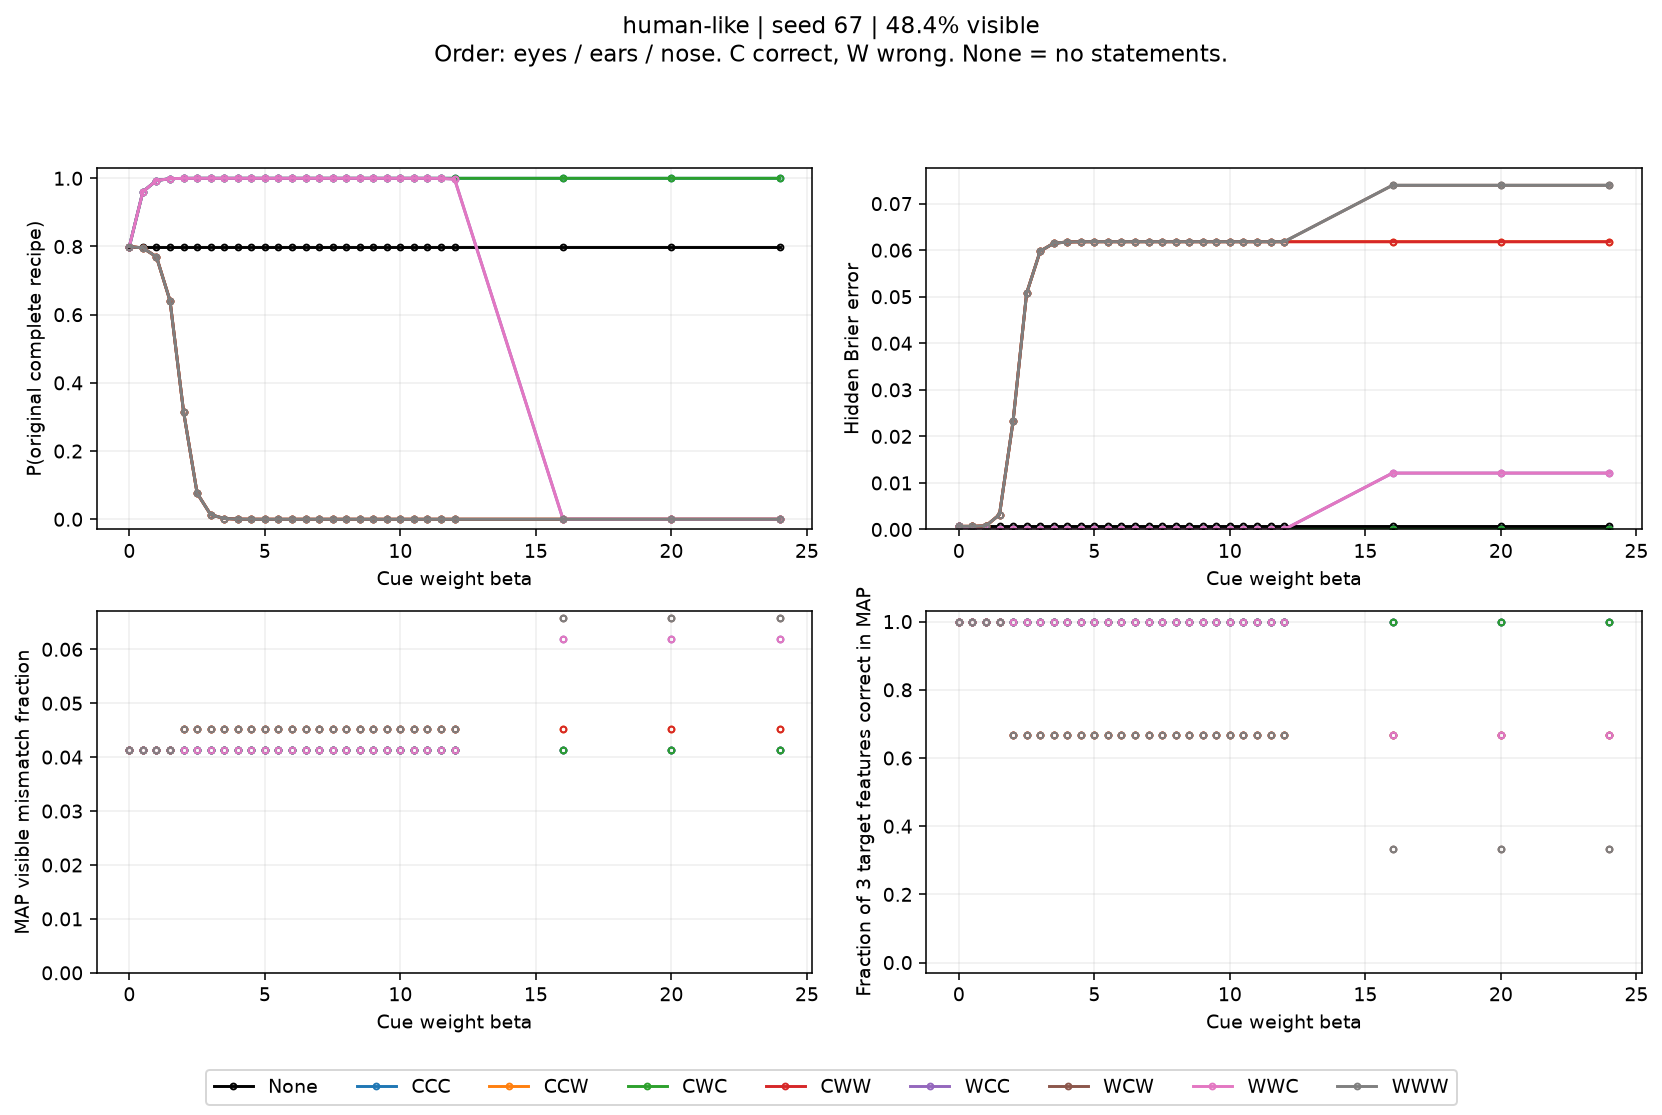

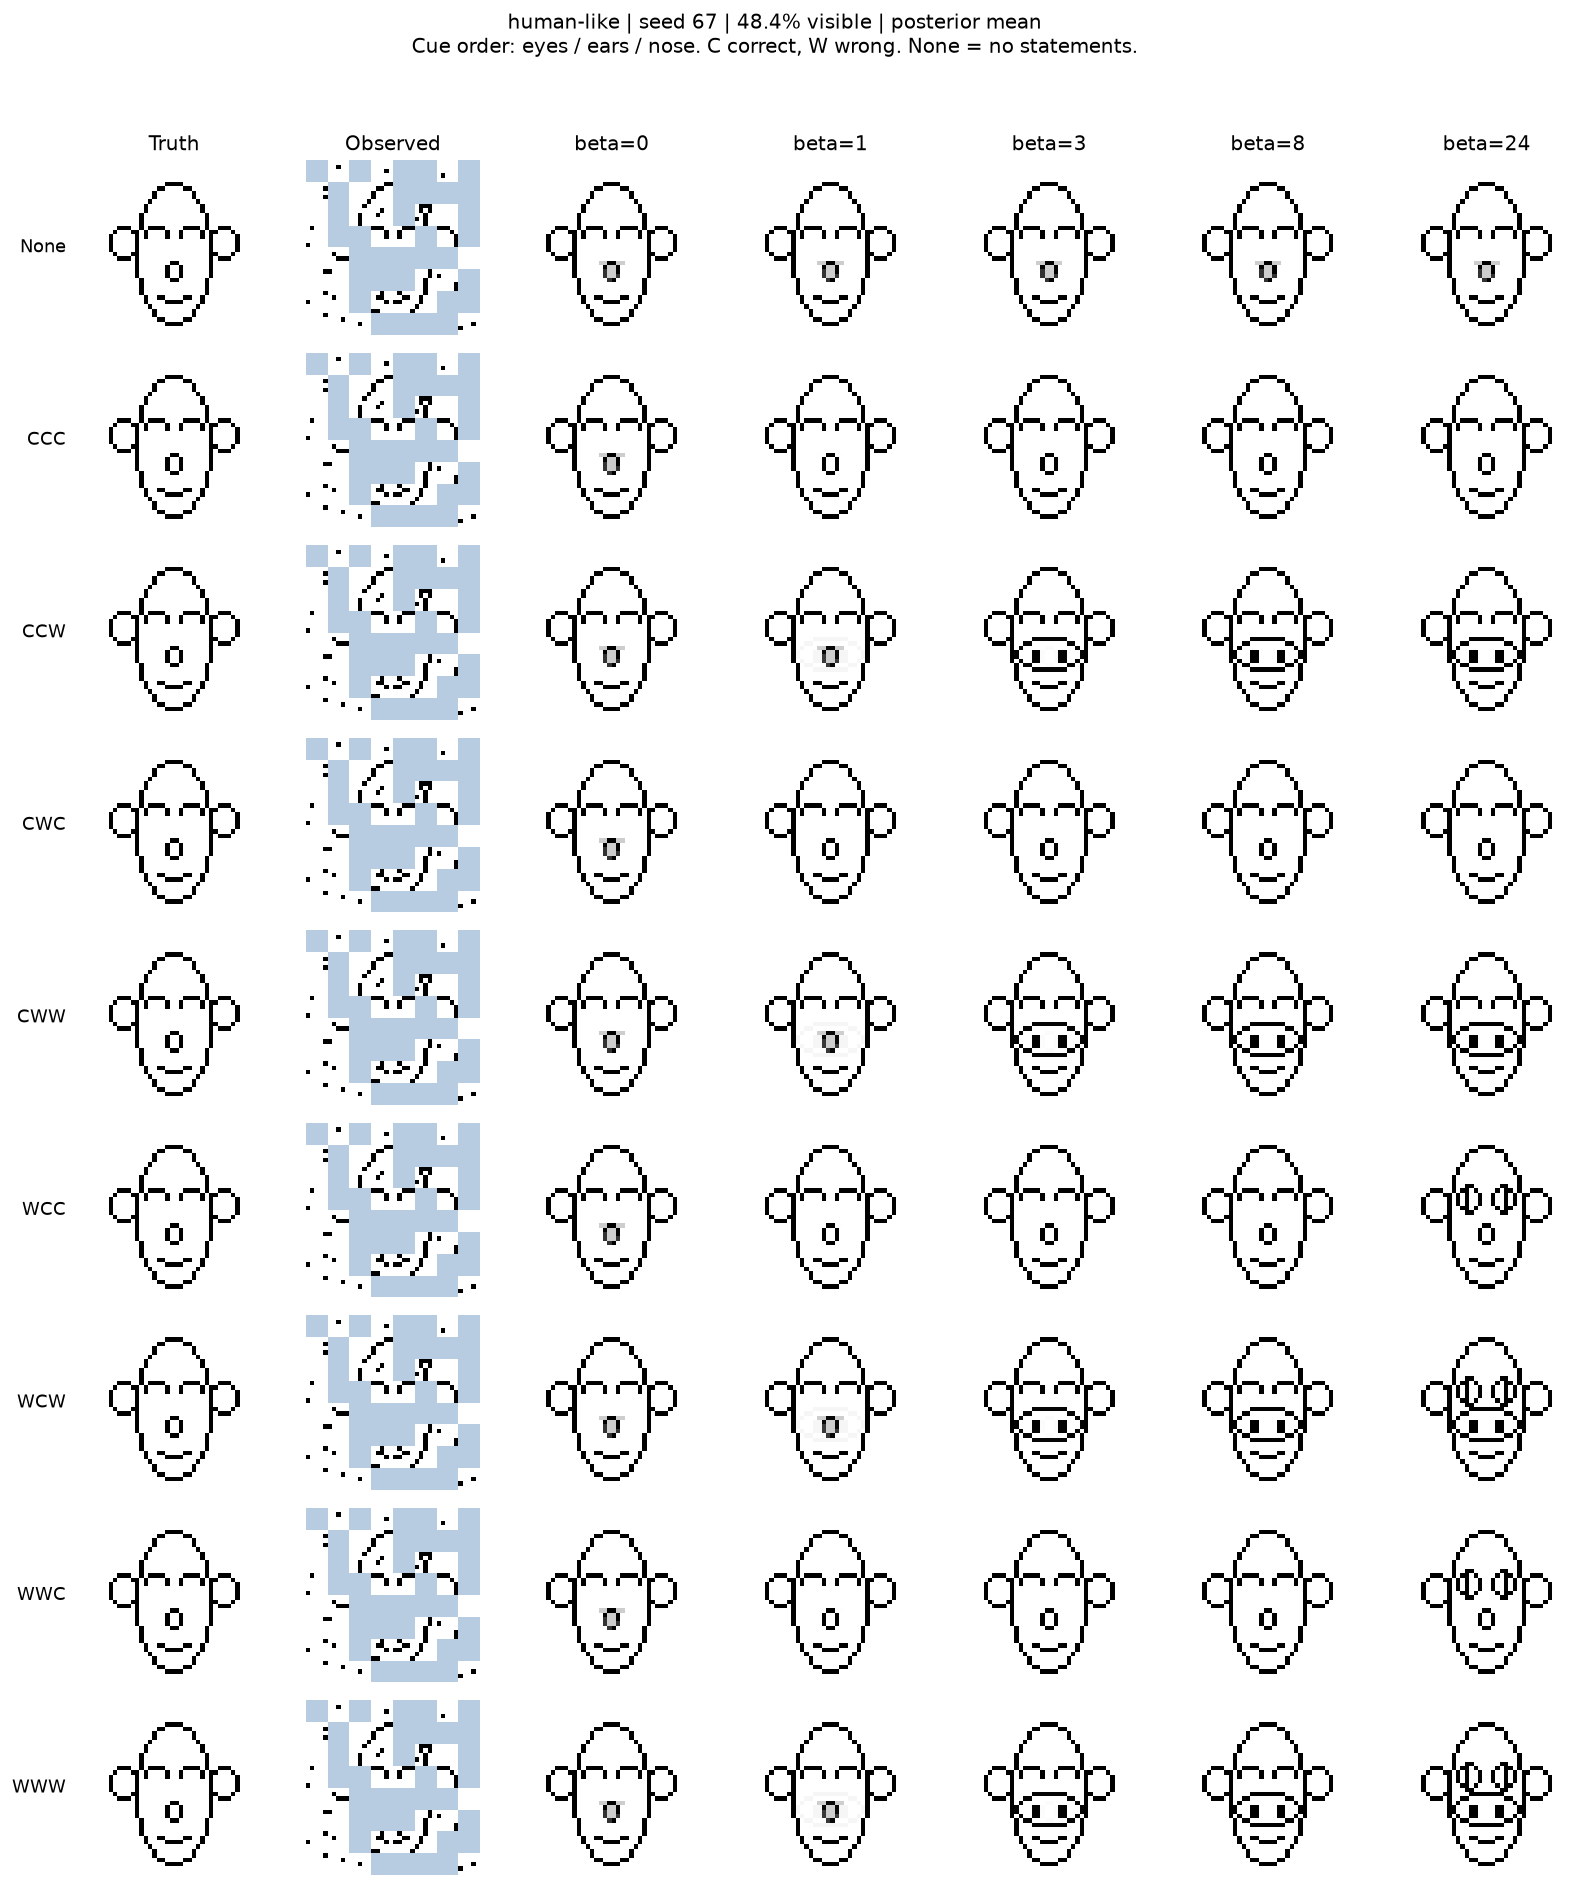

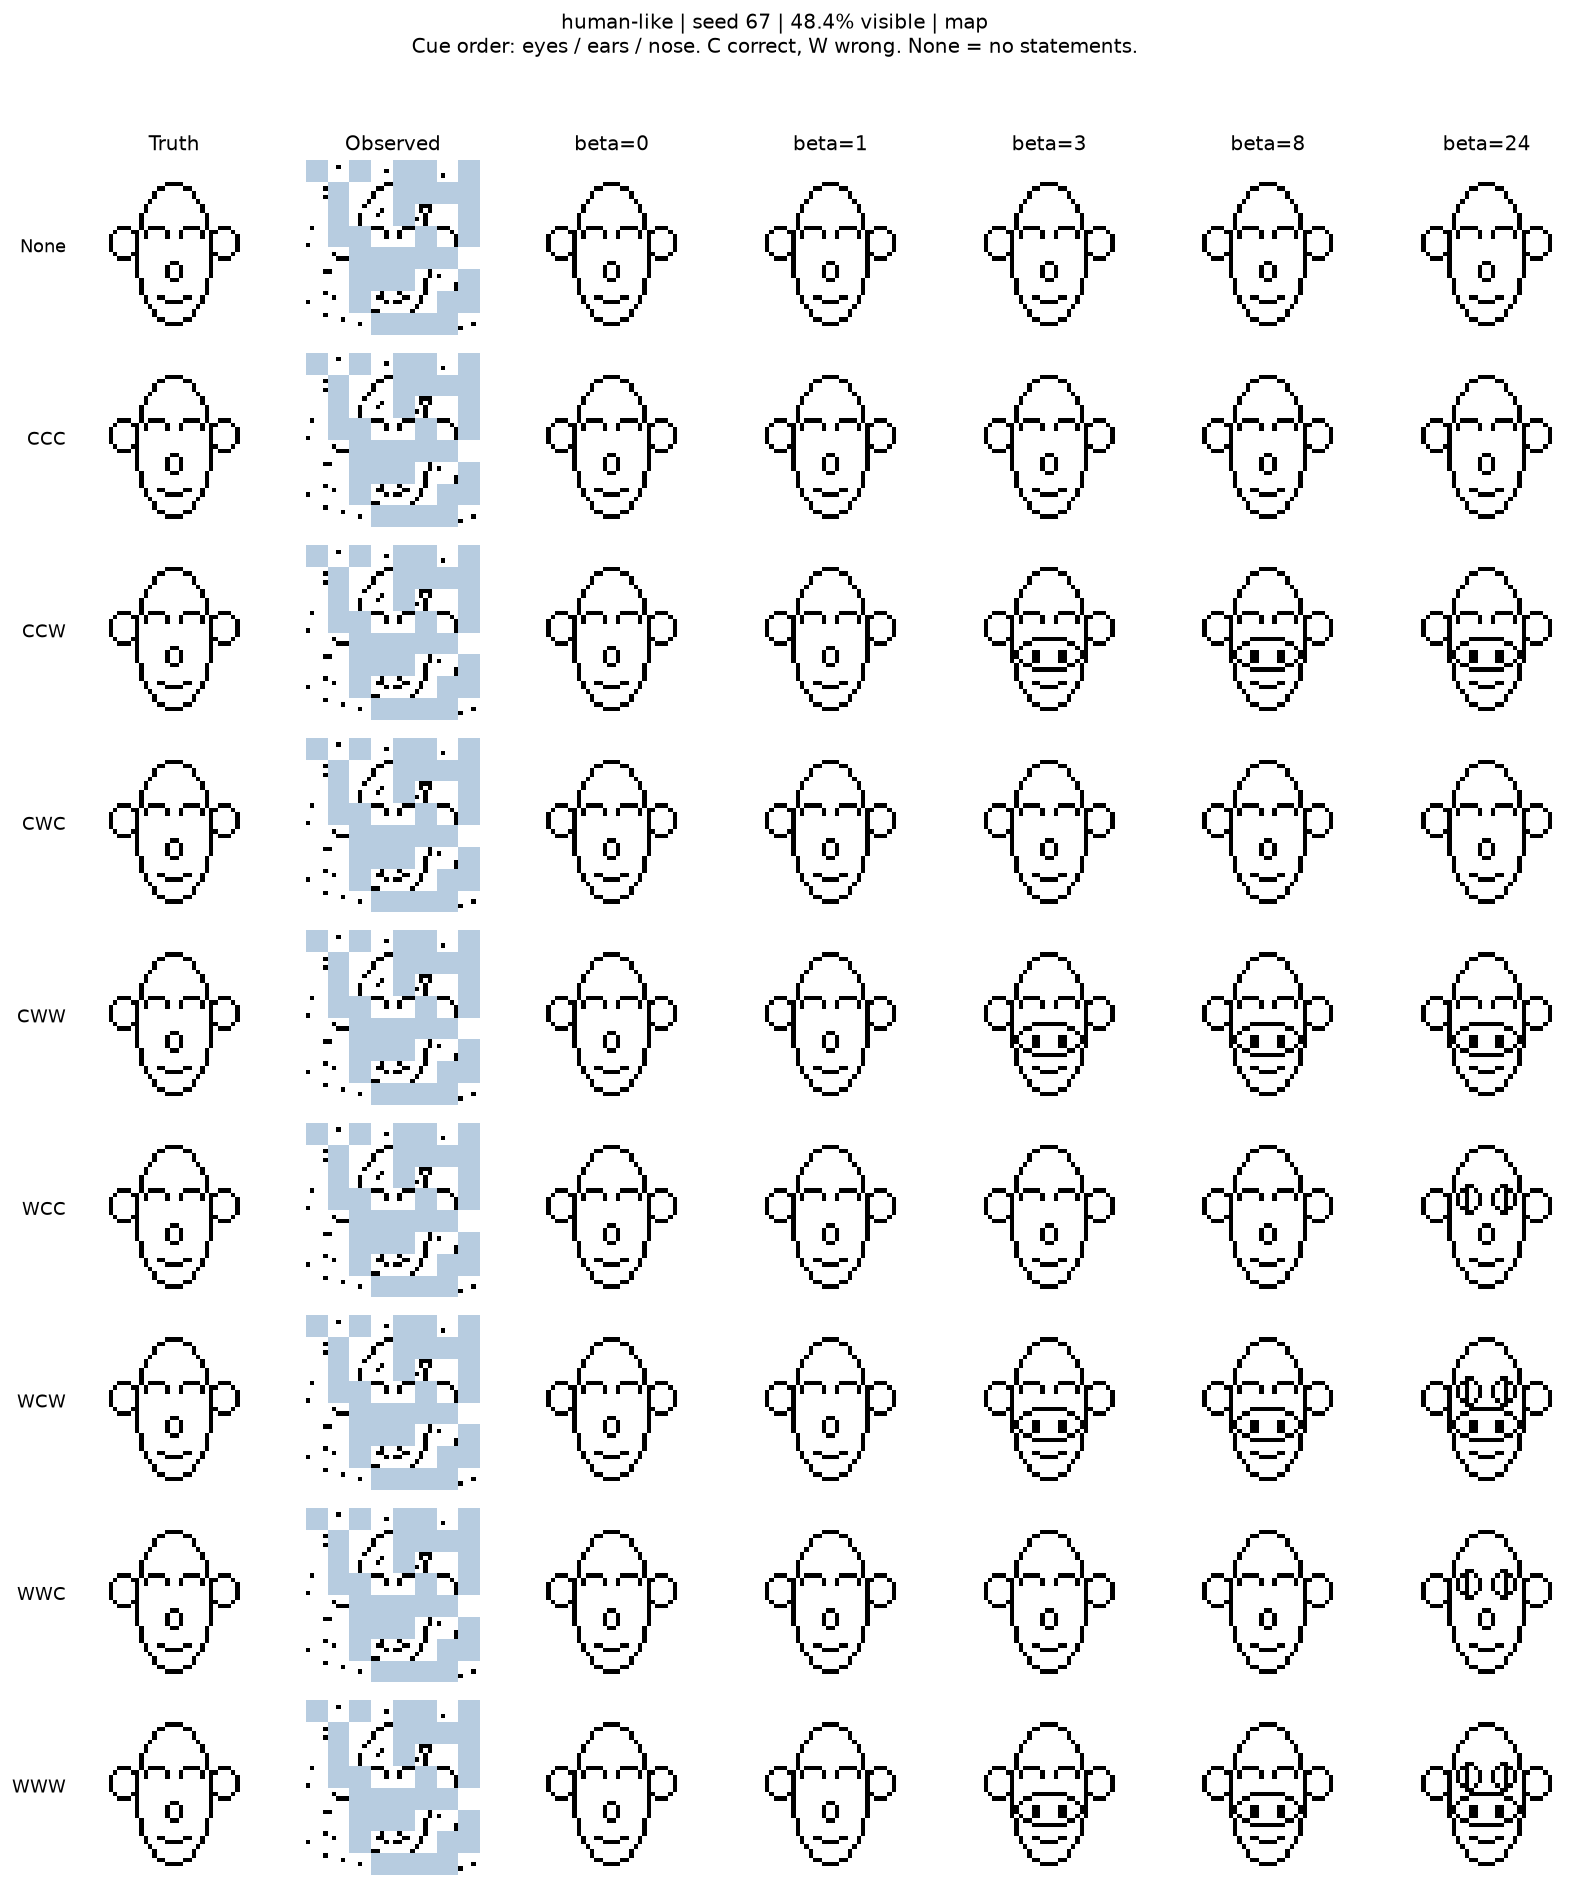

In [3]:
import csv
from IPython.display import display, Image
with (OUT / "metrics.csv").open(encoding="utf-8") as handle:
    rows = list(csv.DictReader(handle))
def example_score(case):
    selected = [row for row in rows if row["case"] == case["case"] and float(row["cue_weight"]) == 3]
    return len({row["map_state"] for row in selected}), case["actual_visibility"]
example = max(manifest["cases"], key=example_score)
print("Displayed case:", example["case"])
print("Original recipe:", example["recipe"])
for pattern, statements in example["statements"].items():
    print(pattern, statements)
for filename in ("cue_weight_sweep.png", "faces_posterior_mean.png", "faces_map.png"):
    display(Image(filename=str(OUT / example["case"] / filename)))


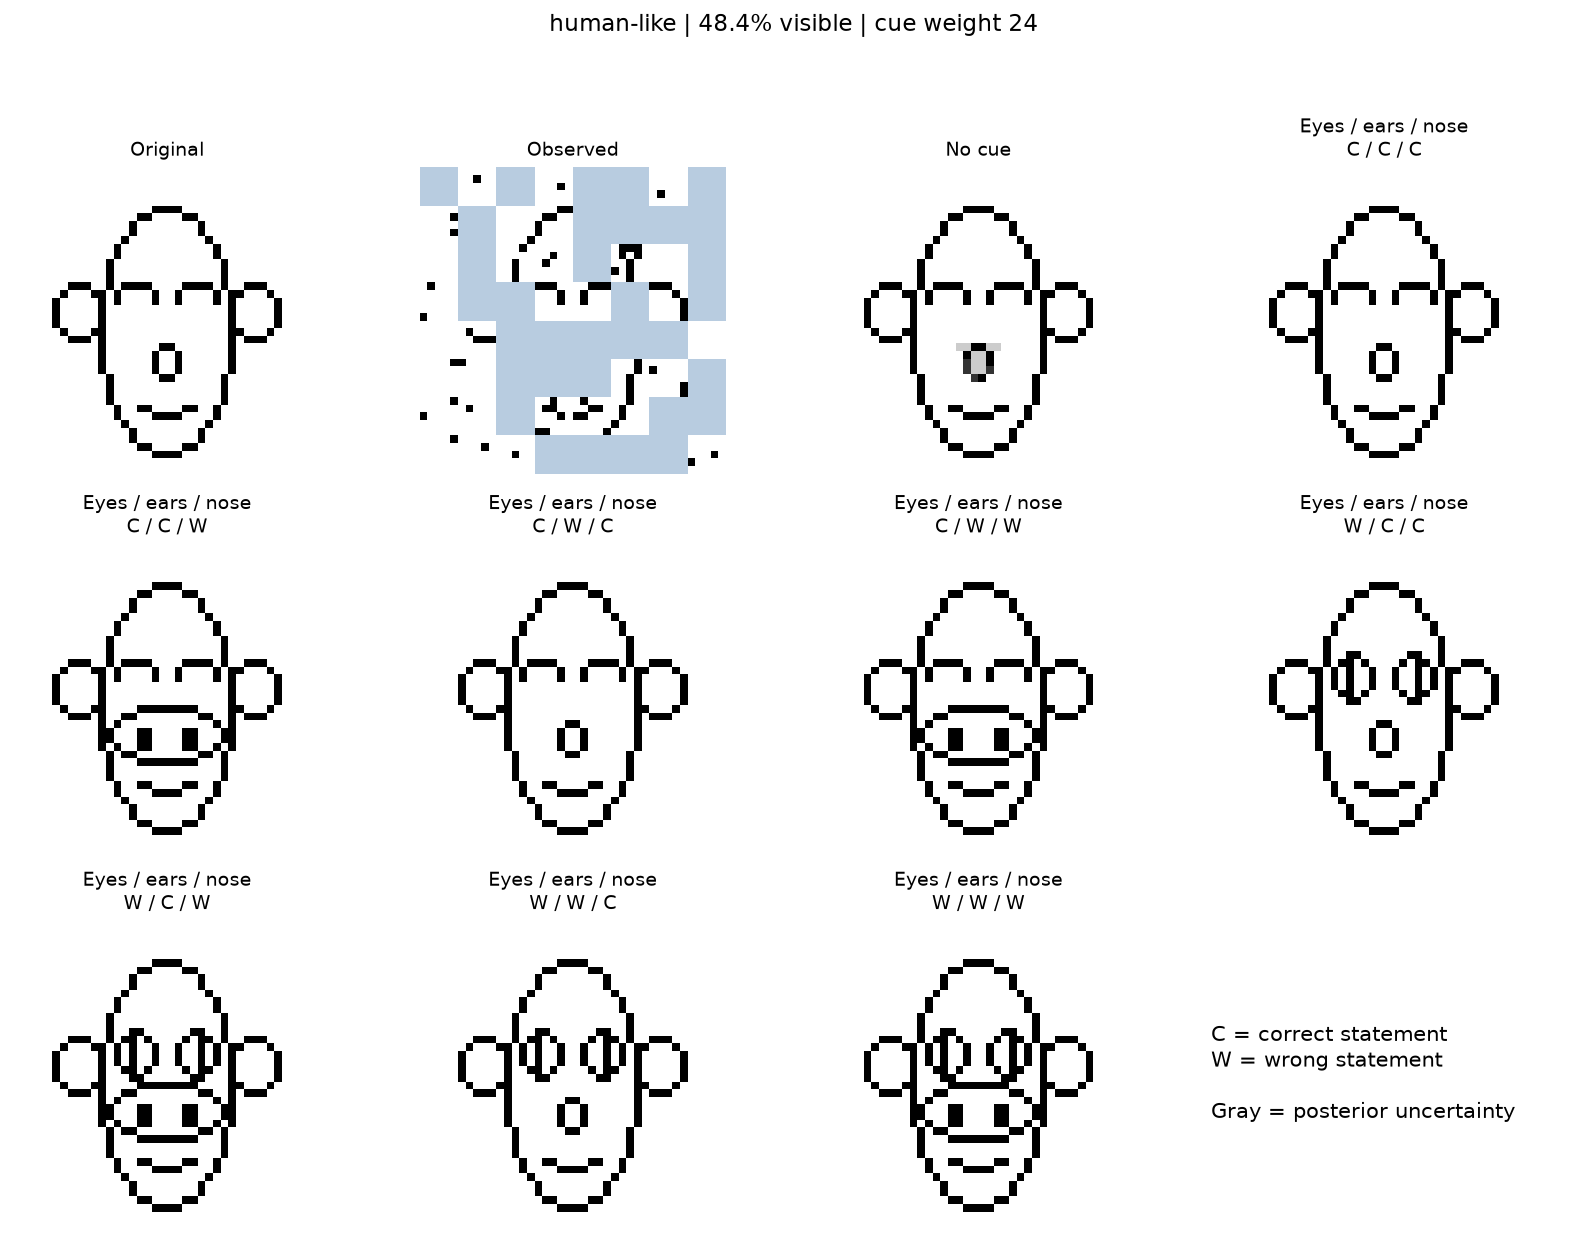

In [4]:
import matplotlib.pyplot as plt
from PIL import Image as PILImage
comparison_weight = max(FACE_WEIGHTS)
from computationalExperiments.face_completion.sweep_mixed_feature_hints import PATTERNS, weight_slug
folder = OUT / example["case"]
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
images = [("Original", folder / "truth.png"), ("Observed", folder / "observation.png")]
for pattern in PATTERNS:
    label = "No cue" if pattern == "None" else "Eyes / ears / nose\n" + " / ".join(pattern)
    images.append((label, folder / "faces" / pattern / weight_slug(comparison_weight) / "posterior_mean.png"))
for ax, (label, path) in zip(axes.flat, images):
    with PILImage.open(path) as face:
        ax.imshow(face, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    ax.set_title(label, fontsize=10)
    ax.axis("off")
axes.flat[-1].axis("off")
axes.flat[-1].text(.05, .5, "C = correct statement\nW = wrong statement\n\nGray = posterior uncertainty", va="center", fontsize=11)
fig.suptitle(f"{example['category']} | {example['actual_visibility']:.1%} visible | cue weight {comparison_weight:g}")
fig.tight_layout(rect=(0, 0, 1, .95))
fig.savefig(OUT / "mixed_cue_faces.png", dpi=140, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(OUT / "mixed_cue_faces.png")))
